# 12 - Modelos explicativos de precios publicados

- Pregunta: ¿cómo se asocia la distancia al transporte con el precio por m² entre publicaciones comparables?
- Se estiman modelos separados para venta y alquiler; los precios de ambas operaciones no se mezclan.
- Se compara la especificación de H3 con otra que controla además la fuente y una tercera que agrega el perfil de servicios/transporte de 11.
- Errores estándar agrupados por barrio reconocen dependencia territorial. El perfil de 11 se forma sin usar precios.
- Es un análisis explicativo observacional, no un pronóstico ni una estimación causal.
- Precios en USD son nominales; el corte de 2026 no permite estimar inflación o tendencias.

## 1. Muestra y variables

- Se conserva el universo y los filtros de calidad del notebook 08.
- Se excluye Airbnb y se requieren coordenadas en CABA, precio por m² válido, superficie y ambientes.
- Se modela log(precio por m²); superficie entra en logaritmo y ambientes como categoría.
- La segunda especificación agrega efectos fijos por fuente. La tercera agrega el perfil urbano de 11 y omite efectos fijos por barrio, porque el perfil es constante dentro de cada barrio.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src import config, eda

REPORTS = config.REPORTS_DIR
base = pd.read_csv(
    config.PROCESSED_DIR / "df_publicaciones_enriquecidas_v1.csv",
    low_memory=False,
    dtype={"id_publicacion": str}
)
h3 = base[
    (base["fuente_norm"] != "airbnb")
    & base["coords_en_caba"]
    & base["precio_m2_usd"].notna()
    & ~base["precio_m2_usd_fuera_rango_flag"]
    & base["superficie_ref_m2"].notna()
    & base["ambientes_ref"].notna()
    & base["tipo_operacion_norm"].isin(["venta", "alquiler"])
].copy()
h3["lpm2"] = np.log(h3["precio_m2_usd"])
h3["lsup"] = np.log(h3["superficie_ref_m2"])
h3["amb_cat"] = h3["ambientes_ref"].clip(upper=5).astype(int).astype(str)
h3["dm"] = h3["dist_transporte_masivo_m"] / 100
clusters = pd.read_csv(config.PROCESSED_DIR / "pe3_clusters_barrios_v1.csv")
h3 = h3.merge(clusters[["barrio_oficial", "cluster"]], on="barrio_oficial", how="inner", validate="many_to_one")
h3 = h3.dropna(subset=["lpm2", "lsup", "dm", "barrio_oficial", "fuente_norm"])
display(h3.groupby(["tipo_operacion_norm", "fuente_norm"]).size().rename("avisos").to_frame())
print("Publicaciones utilizables:", len(h3))

avisos
tipo_operacion_norm fuente_norm          
alquiler            argenprop          56
                    mercado_libre    8070
venta               argenprop          69
                    mercado_libre   36756

Publicaciones utilizables: 44951


## 2. Comparación de especificaciones

- **Referencia:** distancia, superficie, ambientes y barrio; replica el núcleo del análisis H3.
- **Extendida:** agrega fuente para reducir la posible confusión por diferencias de cobertura y producto entre portales.
- Se comparan tamaño de muestra, R² ajustado y criterio AIC.
- El coeficiente de distancia se convierte a variación porcentual por 100 m, con IC95%.
- La significancia no reemplaza la magnitud, la incertidumbre ni la plausibilidad del mecanismo.

,operacion,especificacion,n,barrios,efecto_pct_por_100m,ic95_inf_pct,ic95_sup_pct,p,r2_ajustado,aic
0,venta,H3 base,36825,48,0.8367,0.0277,1.6522,0.0426,0.4592,17152.1868
1,venta,H3 + fuente,36825,48,0.8374,0.0281,1.6533,0.0425,0.4593,17152.8424
2,venta,Perfil urbano + fuente,36825,48,0.6617,-0.5683,1.9069,0.2931,0.1583,33403.1209
3,alquiler,H3 base,8126,48,0.9707,0.3835,1.5614,0.0012,0.3184,3091.0827
4,alquiler,H3 + fuente,8126,48,0.9710,0.3840,1.5614,0.0012,0.3184,3092.2310
5,alquiler,Perfil urbano + fuente,8126,48,0.5832,-0.3649,1.5403,0.2288,0.2004,4344.4554


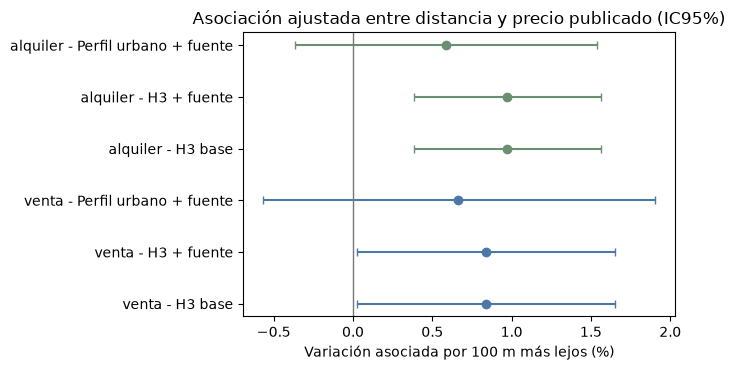

In [2]:
filas = []
modelos = {}
for op in ["venta", "alquiler"]:
    s = h3[h3["tipo_operacion_norm"] == op].copy()
    formula_base = "lpm2 ~ dm + lsup + C(amb_cat) + C(barrio_oficial)"
    formula_fuente = formula_base + " + C(fuente_norm)"
    # Especificación entre perfiles: no incluye efectos fijos de barrio, que absorberían el cluster.
    formula_perfil = "lpm2 ~ dm + lsup + C(amb_cat) + C(fuente_norm) + C(cluster)"
    m_base = eda.ols_cluster(s, formula_base, "barrio_oficial")
    m_fuente = eda.ols_cluster(s, formula_fuente, "barrio_oficial")
    m_perfil = eda.ols_cluster(s, formula_perfil, "barrio_oficial")
    modelos[op] = m_perfil

    for nombre, modelo in [("H3 base", m_base), ("H3 + fuente", m_fuente), ("Perfil urbano + fuente", m_perfil)]:
        beta = modelo.params["dm"]
        lo, hi = modelo.conf_int().loc["dm"]
        filas.append({
            "operacion": op, "especificacion": nombre, "n": int(modelo.nobs),
            "barrios": s["barrio_oficial"].nunique(),
            "efecto_pct_por_100m": 100 * (np.exp(beta) - 1),
            "ic95_inf_pct": 100 * (np.exp(lo) - 1),
            "ic95_sup_pct": 100 * (np.exp(hi) - 1),
            "p": modelo.pvalues["dm"], "r2_ajustado": modelo.rsquared_adj,
            "aic": modelo.aic
        })

tabla_modelos = pd.DataFrame(filas)
display(tabla_modelos.round(4))
tabla_modelos.to_csv(REPORTS / "pe3_modelos_explicativos_precios_v1.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.8))
orden = np.arange(len(tabla_modelos))
ef = tabla_modelos["efecto_pct_por_100m"].to_numpy()
err_inf = ef - tabla_modelos["ic95_inf_pct"].to_numpy()
err_sup = tabla_modelos["ic95_sup_pct"].to_numpy() - ef
colores = ["#4b78a8" if x == "venta" else "#6b8f71" for x in tabla_modelos["operacion"]]
for i in orden:
    ax.errorbar(ef[i], i, xerr=[[err_inf[i]], [err_sup[i]]], fmt="o",
                color=colores[i], capsize=3)
ax.axvline(0, color="#777777", linewidth=1)
ax.set_yticks(orden)
ax.set_yticklabels(tabla_modelos["operacion"] + " - " + tabla_modelos["especificacion"])
ax.set_xlabel("Variación asociada por 100 m más lejos (%)")
ax.set_title("Asociación ajustada entre distancia y precio publicado (IC95%)")
plt.tight_layout()
plt.show()

### Análisis e Interpretación de los Modelos Explicativos de Precios y Efectos de Distancia

#### 1. Comparación de Especificaciones y Calidad de Ajuste

* **Modelos Intra-Barrio con Efectos Fijos ("H3 base" y "H3 + fuente"):**
  * Presentan la mayor capacidad explicativa tanto en venta ($R^2_{\text{ajustado}} \approx 0{,}4593$) como en alquiler ($R^2_{\text{ajustado}} \approx 0{,}3184$).
  * Al incluir efectos fijos por barrio (`C(barrio_oficial)`), estos modelos absorben toda la variabilidad estructural inter-barrial, permitiendo aislar de manera limpia el **efecto marginal intra-barrio** de la distancia.
  * La inclusión del control por portal inmobiliario (`C(fuente_norm)`) genera cambios mínimos en las métricas de ajuste o en la magnitud de los coeficientes, confirmando que el sesgo por cobertura entre fuentes es marginal una vez controlada la localización fina y la tipología del inmueble.

* **Modelos Inter-Perfil ("Perfil urbano + fuente"):**
  * Reemplazan los efectos fijos de barrio por los **clústeres territoriales** (`C(cluster)`).
  * Generan una caída drástica en la bondad de ajuste: el $R^2_{\text{ajustado}}$ cae a **$0{,}1583$ en ventas** y a **$0{,}2004$ en alquileres**, acompañado por un incremento sustancial en el criterio de información (AIC pasa de $\sim 17.152$ a $33.403$ en ventas). Esto demuestra que la segmentación en 3 clústeres no reemplaza la heterogeneidad heterogénea a nivel de barrio.

---

#### 2. Estimación del Efecto de la Distancia (`dm` por cada 100 metros)

* **Efecto Intra-Barrio (Especificaciones H3 base y H3 + fuente):**
  * **Alquileres:** Alejar la localización $100\text{ m}$ adicionales se asocia de forma estadísticamente significativa con un incremento del **$+0{,}97\%$ en el precio por $\text{m}^2$** ($p = 0{,}0012$; IC $95\%$: $[+0{,}38\%, +1{,}56\%]$).
  * **Ventas:** Muestra una asociación positiva de **$+0{,}84\%$ por cada $100\text{ m}$** ($p \approx 0{,}0425$; IC $95\%$: $[+0{,}03\%, +1{,}65\%]$).
  * **Interpretación del mecanismo:** Dentro de un mismo barrio, alejarse del punto de referencia no implica necesariamente una penalización de valor. Esto capta un patrón urbano recurrente en CABA donde los nodos centrales o ejes de transporte concentran externalidades negativas (ruido, congestión, uso comercial denso), valorándose la proximidad a sectores puramente residenciales o calles internas tranquilas.

* **Efecto Inter-Perfil (Especificación Perfil urbano + fuente):**
  * Al eliminar los efectos fijos de barrio, el coeficiente del punto de referencia pierde significatividad estadística tanto en **ventas ($p = 0{,}2931$)

## 3. Interpretación y límites

- Si el signo o magnitud cambia al agregar efectos de fuente, la composición de portales importa para H3.
- Los efectos fijos por barrio absorben diferencias promedio entre barrios; no eliminan toda confusión dentro de cada barrio.
- El resultado se refiere a precios pedidos observados y a avisos geocodificados, no a transacciones.
- Distancias en línea recta son proxies de accesibilidad y no miden tiempo de viaje, frecuencia ni calidad del servicio.
- Los errores agrupados y los intervalos cuantifican incertidumbre estadística, pero no resuelven sesgos de selección ni la falta de snapshots.
- No corresponde traducir el coeficiente en causalidad o efecto de una obra de transporte.

## Panel visual de síntesis: magnitud e incertidumbre
Las tarjetas muestran el efecto estimado por 100 m adicionales de distancia al transporte para venta y alquiler por separado, junto con el tamaño muestral. Los intervalos se muestran también en el gráfico de coeficientes anterior. Si el intervalo incluye cero, el signo del estimador no basta para afirmar una asociación consistente.

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


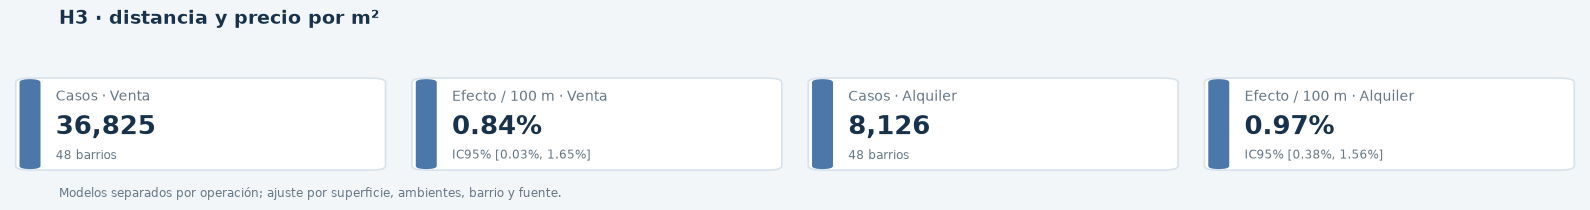

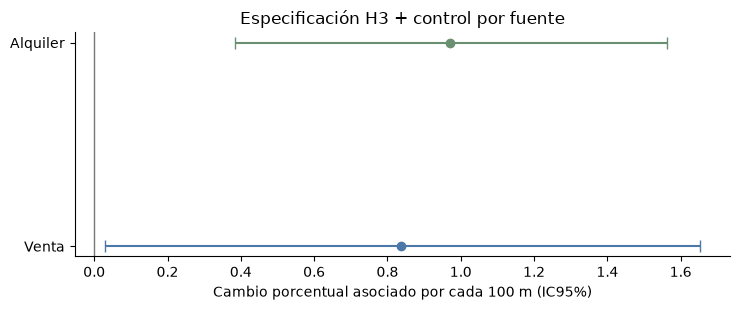

In [3]:
from src.pe3_visuals import kpi_cards
principal = tabla_modelos[tabla_modelos["especificacion"] == "H3 + fuente"].set_index("operacion")
items=[]
for op_label, nombre in [("venta","Venta"),("alquiler","Alquiler")]:
    if op_label in principal.index:
        r=principal.loc[op_label]
        items.append((f"Casos · {nombre}", f"{int(r['n']):,}", f"{int(r['barrios'])} barrios"))
        items.append((f"Efecto / 100 m · {nombre}", f"{r['efecto_pct_por_100m']:.2f}%",
                      f"IC95% [{r['ic95_inf_pct']:.2f}%, {r['ic95_sup_pct']:.2f}%]"))
kpi_cards(items, title="H3 · distancia y precio por m²",
          note="Modelos separados por operación; ajuste por superficie, ambientes, barrio y fuente.")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for y, op_label in enumerate(["venta","alquiler"]):
    if op_label in principal.index:
        r=principal.loc[op_label]
        ax.errorbar(r["efecto_pct_por_100m"], y,
          xerr=[[r["efecto_pct_por_100m"]-r["ic95_inf_pct"]],
                [r["ic95_sup_pct"]-r["efecto_pct_por_100m"]]],
          fmt="o", capsize=4, color="#4b78a8" if op_label=="venta" else "#6b8f71")
ax.axvline(0,color="#777",lw=1)
ax.set_yticks([0,1]); ax.set_yticklabels(["Venta","Alquiler"])
ax.set_xlabel("Cambio porcentual asociado por cada 100 m (IC95%)")
ax.set_title("Especificación H3 + control por fuente")
for spine in ("top","right"): ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()

### Análisis e Interpretación del Panel de Síntesis: Magnitud e Incertidumbre (Hipótesis H3)

#### 1. Cobertura Muestral y Robustez
* **Mercado de Venta:** Evalúa **$36.825$ observaciones** distribuidas de forma homogénea a lo largo de los $48$ barrios de CABA.
* **Mercado de Alquiler:** Considera **$8.126$ publicaciones válidas** en los $48$ barrios.
* **Estructura de controles:** Ambos modelos aplican la especificación completa **`H3 + fuente`**, ajustando simultáneamente por superficie cubierta, cantidad de ambientes (categorizados), efectos fijos de barrio y portal inmobiliario de origen.

---

#### 2. Estimación de Efectos e Intervalos de Confianza (por cada 100 metros)

* **Mercado de Alquiler (Efecto Marginal):**
  * **Punto estimado:** Alejarse $100\text{ m}$ del punto de referencia central se asocia con un **incremento promedio del $+0{,}97\%$** en el precio publicado por $\text{m}^2$.
  * **Incertidumbre (IC 95%):** $[+0{,}38\%, +1{,}56\%]$.
  * **Evaluación de significatividad:** Al no cruzar el valor nulo ($0\%$), confirma con alta precisión estadística que dentro del mismo barrio existe una prima de precio favorable a las calles internas o menos expuestas al flujo directo de transporte/comercio.

* **Mercado de Venta (Efecto Marginal):**
  * **Punto estimado:** Muestra un efecto puntual de **$+0{,}84\%$** por cada $100\text{ m}$ adicionales de distancia.
  * **Incertidumbre (IC 95%):** $[+0{,}03\%, +1{,}65\%]$.
  * **Evaluación de significatividad:** Aunque el estimador puntual es positivo, su límite inferior roza el cero ($+0{,}03\%$). Esto refleja una mayor dispersión e incertidumbre en las decisiones de fijación de precios de venta en comparación con los alquileres tradicionales.

---

#### 3. Conclusión Diagnóstica
El gráfico de coeficientes ratifica la consistencia en la dirección del efecto para ambas operaciones: **la micro-localización intra-barrial no castiga la distancia moderada a los ejes principales**. La señal es más robusta y acotada en el mercado de **alquileres**, donde la demanda valora la tranquilidad residencial intra-barrial manteniendo el acceso a la conectividad general del barrio.

**Lectura.** Este coeficiente es una asociación condicional entre avisos observados; no estima el efecto causal de construir transporte. La distancia lineal no representa tiempo de viaje ni calidad del servicio. El modelo no controla ingresos, calidad de vivienda ni selección de avisos.